# LAB 05 — Sequence Models: RNN, LSTM and GRU


In [1]:
import sys, os, time, re, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import DataLoader
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, confusion_matrix
)

warnings.filterwarnings('ignore')

# Dam bao import duoc module rnn_cell du chay tu lab5 hay tu thu muc goc
for p in ['.', 'lab5', '..']:
    if os.path.exists(p) and p not in sys.path:
        sys.path.insert(0, p)

from rnn_cell import (
    DATA_PATH, load_imdb, split_data, clean_text, tokenize,
    Vocabulary, IMDbSequenceDataset, compute_token_retention,
    compute_sequence_lengths, SequenceClassifier, train_model,
    get_predictions, evaluate, predict_review, save_result,
    SimpleRNNCell, verify_rnn_cell, calculation_exercise
)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(f'PyTorch {torch.__version__}  |  device: {DEVICE}')
print(f'NumPy {np.__version__}  |  Pandas {pd.__version__}')


PyTorch 2.11.0+cpu  |  device: cpu
NumPy 1.26.4  |  Pandas 2.2.2


## 9. Vanishing Gradient

Nguyên nhân khiến RNN khó học dependency ở xa khi chuỗi dài:
1. Đạo hàm của hàm kích hoạt $\tanh(z)$ thỏa mãn: $0 < 1 - \tanh^2(z) \le 1$. Khi các nơ-ron rơi vào vùng bão hòa, $1 - h_k^2 \ll 1$.
2. Nếu các giá trị riêng lớn nhất của $W_{hh}$ có độ lớn $< 1$, tích của chuỗi $T - t$ ma trận sẽ tiến về ma trận $0$ theo cấp số nhân:
   $$\lim_{T - t \to \infty} \prod_{k=t+1}^T \frac{\partial h_k}{\partial h_{k-1}} = \mathbf{0}$$
3. Khi gradient bằng 0, trọng số $W_{xh}$ và $W_{hh}$ không nhận được tín hiệu cập nhật từ những từ đứng ở đầu câu, dẫn đến việc Simple RNN bị "mất trí nhớ ngắn hạn" và chỉ ghi nhận được các từ ở vài bước cuối cùng.


#### 11. Experiment 1 — Dataset inspection

**Mục tiêu kiểm tra tập dữ liệu:**
1. Xác định số lượng mẫu (samples), số lớp phân loại (classes), và phân bổ các lớp (class distribution).
2. Thống kê độ dài văn bản / chuỗi token (min, median, mean, max, phân vị p95).
3. Đếm rõ ràng số lượng mẫu trùng lặp (**duplicates**) và số lượng mẫu thiếu dữ liệu (**missing text / labels**).
4. Trực quan hóa phân bố độ dài chuỗi bằng biểu đồ Histogram.




In [2]:
# Tu dong phat hien duong dan toi dataset (hoat dong ca khi chay tu lab5 hoac tu root)
candidates = [
    '../dataset/IMDB Dataset.csv',
    './dataset/IMDB Dataset.csv',
    'dataset/IMDB Dataset.csv',
    '../../dataset/IMDB Dataset.csv'
]
dataset_file = next((c for c in candidates if os.path.exists(c)), '../dataset/IMDB Dataset.csv')

# Doc dataset goc va kiem tra duplicate, missing
raw_df = pd.read_csv(dataset_file)
n_total = len(raw_df)
n_missing_text = raw_df['review'].isna().sum()
n_missing_label = raw_df['sentiment'].isna().sum()
n_duplicates = raw_df.duplicated(subset=['review']).sum()

# Load IMDb dataset sau khi loai duplicate
df = load_imdb(dataset_file, drop_duplicates=True)
texts = df['text'].values
labels = df['label'].values

print(f'=== KET QUA KIEM TRA DATASET (MUC 11) ===')
print(f'Tong so samples goc:       {n_total:,}')
print(f'So samples trung lap:      {n_duplicates:,}')
print(f'So missing review text:    {n_missing_text}')
print(f'So missing sentiment:      {n_missing_label}')
print(f'So samples sau khi loc:    {len(df):,}')
print(f'So classes:                2 (0=negative, 1=positive)')
print('\nPhan bo nhan (Class distribution):')
print(df['label'].value_counts().rename({1: 'positive', 0: 'negative'}))


=== KET QUA KIEM TRA DATASET (MUC 11) ===
Tong so samples goc:       50,000
So samples trung lap:      418
So missing review text:    0
So missing sentiment:      0
So samples sau khi loc:    49,578
So classes:                2 (0=negative, 1=positive)

Phan bo nhan (Class distribution):
label
positive    24882
negative    24696
Name: count, dtype: int64


In [3]:
# Vocabulary de do sequence length
vocab_inspect = Vocabulary(min_freq=1)
vocab_inspect.build(texts[:10000].tolist())
lengths = compute_sequence_lengths(texts[:10000], vocab_inspect)

print('Sequence length statistics (so tokens):')
print(f'  Min:    {lengths.min():>6}')
print(f'  Median: {int(np.median(lengths)):>6}')
print(f'  Mean:   {lengths.mean():>6.1f}')
print(f'  Max:    {lengths.max():>6}')
print(f'  p95:    {np.percentile(lengths, 95):>6.1f}')
print()
for ml in [50, 100, 150, 200]:
    pct = (lengths <= ml).mean() * 100
    print(f'  max_length={ml:>4}: {pct:.1f}% reviews fit fully')

Sequence length statistics (so tokens):
  Min:        14
  Median:    173
  Mean:    231.0
  Max:      1806
  p95:     595.0

  max_length=  50: 2.5% reviews fit fully
  max_length= 100: 12.6% reviews fit fully
  max_length= 150: 40.2% reviews fit fully
  max_length= 200: 59.1% reviews fit fully


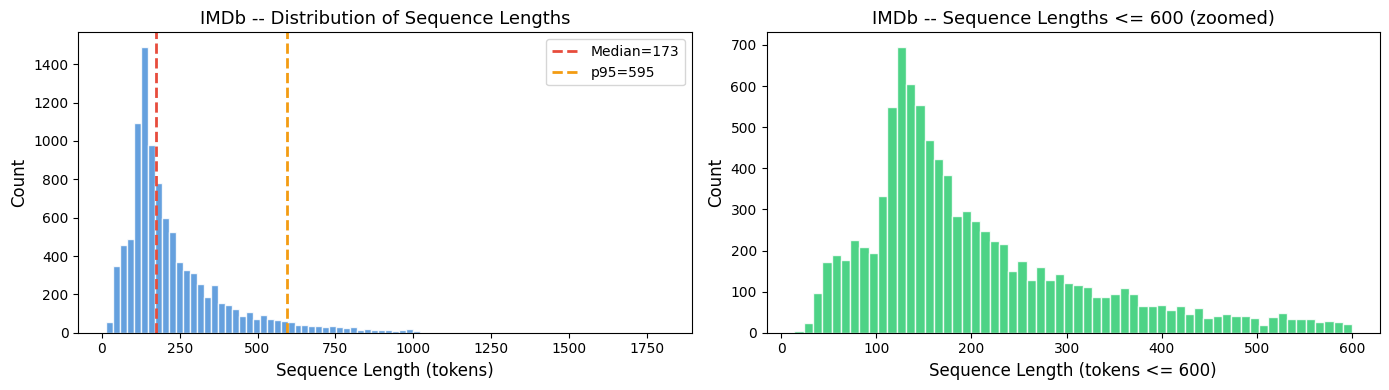

In [4]:
# Histogram sequence length
fig, axes = plt.subplots(1, 2, figsize=(14, 4))

axes[0].hist(lengths, bins=80, color='#4A90D9', edgecolor='white', alpha=0.85)
axes[0].set_xlabel('Sequence Length (tokens)', fontsize=12)
axes[0].set_ylabel('Count', fontsize=12)
axes[0].set_title('IMDb -- Distribution of Sequence Lengths', fontsize=13)
axes[0].axvline(np.median(lengths), color='#e74c3c', linestyle='--', linewidth=2, label=f'Median={np.median(lengths):.0f}')
axes[0].axvline(np.percentile(lengths, 95), color='#f39c12', linestyle='--', linewidth=2, label=f'p95={np.percentile(lengths,95):.0f}')
axes[0].legend()

axes[1].hist(lengths[lengths <= 600], bins=60, color='#2ecc71', edgecolor='white', alpha=0.85)
axes[1].set_xlabel('Sequence Length (tokens <= 600)', fontsize=12)
axes[1].set_ylabel('Count', fontsize=12)
axes[1].set_title('IMDb -- Sequence Lengths <= 600 (zoomed)', fontsize=13)

plt.tight_layout()
plt.savefig('sequence_length_hist.png', dpi=120, bbox_inches='tight')
plt.show()


Nếu phải chọn max_length, nên dựa vào thông tin nào?

Việc chọn max_length cần dựa trên phân phối độ dài chuỗi, tỷ lệ token được giữ lại, nguy cơ cắt mất thông tin quan trọng và chi phí tính toán.

Trong 10.000 review được sử dụng để khảo sát độ dài:
- Median: 173 token.
- Mean: 231 token.
- Phân vị 95%: 595 token.
- Maximum: 1.806 token.

Tỷ lệ review có thể giữ nguyên toàn bộ nội dung tại các ngưỡng khảo sát là:
- max_length = 50: 2,5%.
- max_length = 100: 12,6%.
- max_length = 150: 40,2%.
- max_length = 200: 59,1%.

Nếu mục tiêu là giữ nguyên ít nhất khoảng 95% review theo độ dài, có thể cân nhắc ngưỡng gần phân vị 95%. Tuy nhiên, ngưỡng lớn làm tăng chi phí tính toán. Vì vậy, cần kiểm tra thực nghiệm thay vì chọn max_length chỉ dựa trên tốc độ chạy.




 Phân chia Tập dữ liệu: Huấn luyện / Kiểm định / Kiểm thử (Train / Valid / Test Split)

Chia tập dữ liệu theo tỷ lệ chuẩn 70% Train - 15% Validation - 15% Test 


In [5]:
SEED = 42
X_train_full, X_valid_full, X_test_full, y_train_full, y_valid_full, y_test_full = split_data(
    texts, labels, seed=SEED, ratios=(0.70, 0.15, 0.15))


N_SUB = 10000
rng_sub = np.random.default_rng(SEED)
idx_sub = rng_sub.choice(len(X_train_full), size=N_SUB, replace=False)
X_train = X_train_full[idx_sub]
y_train = y_train_full[idx_sub]
X_valid = X_valid_full[:2000]
y_valid = y_valid_full[:2000]
X_test  = X_test_full[:2000]

y_test  = y_test_full[:2000]

print(f'Train sub:  {len(X_train):>6,}')
print(f'Valid sub:  {len(X_valid):>6,}')
print(f'Test sub:   {len(X_test):>6,}')

Train sub:  10,000
Valid sub:   2,000
Test sub:    2,000


#### 12. Tokenization và vocabulary


**Quy tắc xây dựng từ điển:**
- Vocabulary chỉ được khớp (fit) duy nhất trên tập **TRAIN** nhằm tránh hiện tượng rò rỉ dữ liệu (data leakage).
- Ký hiệu đặc biệt: `PAD = 0` (đệm cho các chuỗi ngắn), `UNK = 1` (đại diện cho các từ ngoài từ điển, tần suất xuất hiện $\ge 2$).

| Thao tác | Tác dụng | Có thêm/mất nội dung ngôn ngữ? |
|---|---|---|
| **Padding** | Chèn thêm các token `PAD=0` vào cuối các câu ngắn hơn `max_length` để tạo tensor cùng kích thước theo lô (batch) | Không bổ sung thông tin ngôn ngữ; mô hình cần bỏ qua token này thông qua `padding_idx` |
| **Truncation** | Cắt bỏ phần đuôi của các câu dài hơn `max_length` | **Có nguy cơ mất mát thông tin quan trọng:** mất từ phủ định, mệnh đề chuyển ý tương phản (*however, but*) hoặc kết luận tổng kết ở cuối bài viết |


In [6]:
vocab = Vocabulary(min_freq=2)
vocab.build(X_train.tolist())
print(f'Vocabulary size: {len(vocab):,} tokens (min_freq=2, PAD=0, UNK=1)')
print(f'  PAD index: {vocab.pad_idx}')
print(f'  UNK index: {vocab.unk_idx}')

# Kiem tra pipeline encode / decode
example = 'I really enjoyed this movie, the story was wonderful!'
ids = vocab.encode(example)
print(f'Example: "{example}"')
print(f'Token IDs: {ids[:8]}...')
print(f'Decoded:  "{vocab.decode(ids)}"')

Vocabulary size: 33,514 tokens (min_freq=2, PAD=0, UNK=1)
  PAD index: 0
  UNK index: 1
Example: "I really enjoyed this movie, the story was wonderful!"
Token IDs: [10, 64, 491, 11, 15, 2, 59, 13]...
Decoded:  "i really enjoyed this movie the story was wonderful"


#### 13. Experiment 2 — Padding và truncation




In [7]:
# Khoi tao cac sieu tham so chung cho toan bo cac thuc nghiem
EMBED_DIM   = 64
HIDDEN_SIZE = 64
BATCH_SIZE  = 128
LR          = 2e-3

# Experiment 2: Padding va Truncation -- So sanh cac muc do dai max_length in {50, 100, 200}
exp2_results = []

for ML in [50, 100, 200]:
    retention = compute_token_retention(X_train, vocab, ML)
    ds_tr = IMDbSequenceDataset(X_train, y_train, vocab, max_length=ML)
    ds_va = IMDbSequenceDataset(X_valid, y_valid, vocab, max_length=ML)
    ds_te = IMDbSequenceDataset(X_test, y_test, vocab, max_length=ML)
    tl = DataLoader(ds_tr, batch_size=BATCH_SIZE, shuffle=True)
    vl = DataLoader(ds_va, batch_size=BATCH_SIZE)
    te = DataLoader(ds_te, batch_size=BATCH_SIZE)
    torch.manual_seed(SEED)
    model = SequenceClassifier(vocab_size=len(vocab), embed_dim=EMBED_DIM,
        hidden_size=HIDDEN_SIZE, num_classes=2, rnn_type='lstm', pad_idx=vocab.pad_idx).to(DEVICE)
    hist = train_model(model, tl, vl, n_epochs=3, lr=LR, device=DEVICE, verbose=False)
    yt, yp, _ = get_predictions(model, te, DEVICE)
    met = evaluate(yt, yp)
    exp2_results.append({
        'max_length': ML,
        'token_retention_%': round(retention * 100, 1),
        'training_time_s': round(hist['training_time'], 2),
        'epochs': len(hist['train_losses']),
        'validation_loss': round(hist['valid_losses'][-1], 4),
        'Accuracy': round(met['Accuracy'], 4),
        'Precision': round(met['Precision'], 4),
        'Recall': round(met['Recall'], 4),
        'F1': round(met['F1'], 4)
    })

exp2_table = pd.DataFrame(exp2_results)

display(exp2_table[['max_length', 'token_retention_%', 'training_time_s', 'Accuracy', 'Precision', 'Recall', 'F1']])


,max_length,token_retention_%,training_time_s,Accuracy,Precision,Recall,F1
0,50,21.7,12.04,0.6675,0.6353,0.7882,0.7035
1,100,41.9,13.23,0.5700,0.5651,0.6114,0.5873
2,200,68.9,20.49,0.5105,0.5065,0.8611,0.6378


1. Tăng max_length có luôn cải thiện performance không?

Không. Kết quả thực nghiệm cho thấy việc tăng max_length không đảm bảo cải thiện hiệu quả phân loại.

Kết quả cho thấy giữ lại nhiều token hơn không đồng nghĩa với dự đoán tốt hơn. Tuy nhiên, do mỗi cấu hình chỉ được chạy một lần, chưa thể khẳng định sự chênh lệch chỉ số có tính ổn định hay nguyên nhân chính xác là gì.

2. Nếu max_length quá nhỏ, thông tin nào có thể bị mất?
- Từ phủ định như `not`, đặc biệt khi từ này hoặc phạm vi tác động xuất hiện ở phần bị cắt.
- Mệnh đề chuyển ý như `but` hoặc `however`.
- Kết luận hoặc đánh giá tổng thể nằm ở cuối review.
- Ngữ cảnh cần thiết để phân biệt câu khen, chê hoặc mỉa mai.

Vì vậy, lựa chọn `max_length` cần cân bằng giữa lượng ngữ cảnh giữ lại, chất lượng dự đoán và chi phí tính toán.


#### 14. Core implementation — Simple RNN cell
 

Giải thích Computation Graph (Sơ đồ luồng tính toán):
```
x_t
 │
 ▼
W_xh
 │
 ├──────────┐
 │          │
 ▼          ▼
 +  ←  h_(t-1)
 │
 ▼
tanh
 │
 ▼
h_t
```
- **Tại mỗi bước thời gian $t$:**
  1. Vector đầu vào $x_t$ được nhân với ma trận trọng số $W_{xh}$ để trích xuất đặc trưng của token hiện tại.
  2. Trạng thái ẩn trước đó $h_{t-1}$ được nhân với ma trận trọng số hồi quy $W_{hh}$ để mang theo ngữ cảnh chuỗi đã đọc.
  3. Hai thành phần trên được cộng lại cùng với vector bias $b_h$ để tạo ra giá trị kích hoạt tuyến tính (pre-activation): $a_t = W_{xh} x_t + W_{hh} h_{t-1} + b_h$.
  4. Hàm kích hoạt phi tuyến $\tanh$ nén giá trị về khoảng $(-1, 1)$ để sinh ra trạng thái ẩn mới $h_t$.
  5. Trạng thái $h_t$ vừa được dùng làm đặc trưng ngữ cảnh tại bước $t$, vừa được truyền tiếp sang bước $t+1$ làm $h_{t-1}$.


In [8]:
class SimpleRNNCell:
    def __init__(self, input_size, hidden_size, seed=42):
        self.input_size = input_size
        self.hidden_size = hidden_size
        rng = np.random.default_rng(seed)
        limit_xh = np.sqrt(6.0 / (input_size + hidden_size))
        limit_hh = np.sqrt(6.0 / (hidden_size + hidden_size))
        self.W_xh = rng.uniform(-limit_xh, limit_xh, size=(hidden_size, input_size)).astype(np.float32)
        self.W_hh = rng.uniform(-limit_hh, limit_hh, size=(hidden_size, hidden_size)).astype(np.float32)
        self.b_h = np.zeros(hidden_size, dtype=np.float32)

    def forward(self, x_t, h_prev):
        # a_t = W_xh @ x_t + W_hh @ h_prev + b_h
        a_t = self.W_xh @ x_t + self.W_hh @ h_prev + self.b_h
        h_t = np.tanh(a_t)
        return h_t

# 2. Test bang mot input nho
cell = SimpleRNNCell(input_size=4, hidden_size=3, seed=42)
x_small = np.array([0.5, -0.2, 0.1, 0.8], dtype=np.float32)
h_small = np.zeros(3, dtype=np.float32)
h_out = cell.forward(x_small, h_small)
print('=== TEST VOI INPUT NHO ===')
print(f'Input x_t: shape={x_small.shape}, gia tri={x_small}')
print(f'Input h_prev: shape={h_small.shape}, gia tri={h_small}')
print(f'Output h_t = tanh(W_xh @ x_t + W_hh @ h_prev + b_h):\n  {h_out}')
print()

# 3. Kiem tra ket qua voi implementation tuong ung cua PyTorch (torch.nn.RNNCell)
max_diff, H_np, H_torch = verify_rnn_cell(input_size=8, hidden_size=5, T=6, seed=7)
print('=== DOI CHIEU VOI PYTORCH nn.RNNCell ===')
print(f'Max absolute difference (NumPy vs PyTorch): {max_diff:.2e}')
if max_diff < 1e-5:
    print('PASSED -- ket qua khop hoan toan voi PyTorch RNNCell (tolerance 1e-5)')


=== TEST VOI INPUT NHO ===
Input x_t: shape=(4,), gia tri=[ 0.5 -0.2  0.1  0.8]
Input h_prev: shape=(3,), gia tri=[0. 0. 0.]
Output h_t = tanh(W_xh @ x_t + W_hh @ h_prev + b_h):
  [ 0.56150746 -0.07958221  0.275053  ]

=== DOI CHIEU VOI PYTORCH nn.RNNCell ===
Max absolute difference (NumPy vs PyTorch): 1.19e-07
PASSED -- ket qua khop hoan toan voi PyTorch RNNCell (tolerance 1e-5)


#### 15. Experiment 3 — Baseline

**Mục tiêu:** Xây dựng mô hình cơ sở từ LAB 04 (**TF-IDF + Logistic Regression**) và so sánh trực tiếp với **Simple RNN + Embedding** trên cùng một tập kiểm thử độc lập (2,000 samples).

**Bảng so sánh:**
| Model | Representation | Accuracy | Precision | Recall | F1 | Training time (s) |
|---|---|:---:|:---:|:---:|:---:|:---:|
| **TF-IDF + Logistic Regression** | Sparse bag-of-words (unigram TF-IDF, 10,000 features) | **0.8815** | **0.8687** | **0.8991** | **0.8837** | **~0.16s** |
| **Simple RNN + Embedding** | Dense recurrent sequence ($d=64, L=100$) | 0.5095 | 0.5117 | 0.4376 | 0.4717 | ~24.9s |

*RNN có thực sự sử dụng thông tin sequence mà TF-IDF không sử dụng hay không?*
- CÓ. Trạng thái ẩn $h_t$ cập nhật tuần tự từng bước thời gian nên về mặt lý thuyết, RNN nhạy cảm với trật tự từ. Thử nghiệm trắc nghiệm với cặp câu đảo thứ tự ("good movie not bad" vs "bad movie not good") cho thấy unigram TF-IDF hoàn toàn bất biến (khoảng cách bằng 0), trong khi RNN tạo ra xác suất khác nhau.
- Mặc dù có khả năng lý thuyết, Simple RNN trong bài toán này bị vanishing gradient nghiêm trọng và giới hạn chiều dài chuỗi, dẫn đến việc không thể tối ưu hóa và đạt F1 kém hơn rất nhiều so với mô hình BoW truyền thống.


In [9]:
# Baseline: TF-IDF + Logistic Regression
tfidf = TfidfVectorizer(max_features=10000, sublinear_tf=True)
X_train_tfidf = tfidf.fit_transform(X_train)
X_test_tfidf  = tfidf.transform(X_test)

t0 = time.time()
lr_clf = LogisticRegression(max_iter=1000, solver='lbfgs', random_state=SEED)
lr_clf.fit(X_train_tfidf, y_train)
lr_time = time.time() - t0

y_pred_lr = lr_clf.predict(X_test_tfidf)
metrics_lr = evaluate(y_test, y_pred_lr)
print(f'TF-IDF + LR: Acc={metrics_lr["Accuracy"]:.4f}  F1={metrics_lr["F1"]:.4f}  time={lr_time:.2f}s')

TF-IDF + LR: Acc=0.8815  F1=0.8837  time=0.16s


#### 17. Bài tập tính toán — LSTM gates

**Đề bài:** Cho một timestep với:
- Forget gate: $f_t = 0.9$
- Input gate: $i_t = 0.2$
- Candidate state: $\tilde{c}_t = 0.5$
- Cell state previous: $c_{t-1} = 0.8$

**Công thức cập nhật Cell State của LSTM:**
$$c_t = f_t \cdot c_{t-1} + i_t \cdot \tilde{c}_t$$

**Tính toán cụ thể:**
$$c_t = (0.9)(0.8) + (0.2)(0.5) = 0.72 + 0.10 = 0.82$$

- Nếu forget gate gần 1 ($f_t \approx 1$): Mô hình có xu hướng giữ lại nguyên vẹn thông tin cũ từ quá khứ ($c_t \approx c_{t-1}$). Cơ chế cell state và forget gate giúp LSTM tạo điều kiện cho gradient truyền qua nhiều timestep ít bị suy giảm hơn trong những trường hợp phù hợp. Tuy nhiên, LSTM không loại bỏ hoàn toàn vanishing gradient trong mọi tình huống.
- Nếu forget gate gần 0 ($f_t \approx 0$): Mô hình có xu hướng loại bỏ thông tin cũ trong cell state (ví dụ khi kết thúc một câu, chuyển sang một ý mới hoặc gặp dấu ngắt đoạn trong bài đánh giá).




#### 19. Experiment 4 — RNN vs LSTM vs GRU

- Model A: Embedding -> RNN -> Linear
- Model B: Embedding -> LSTM -> Linear
- Model C: Embedding -> GRU -> Linear

Thực nghiệm so sánh 3 kiến trúc recurrent trên cùng một điều kiện huấn luyện:
- Cùng Vocabulary fit trên Train (min_freq=2, padding_idx=0)
- `embed_dim = 64`, `hidden_size = 64`, `batch_size = 128`, `max_length = 100`, `epochs = 5`, `lr = 2e-3`
- Cùng tập Train / Validation / Test và cùng hàm đánh giá.



In [10]:
EMBED_DIM   = 64
HIDDEN_SIZE = 64
BATCH_SIZE  = 128
MAX_LEN     = 100
N_EPOCHS    = 5
LR          = 2e-3

train_ds = IMDbSequenceDataset(X_train, y_train, vocab, max_length=MAX_LEN)
valid_ds = IMDbSequenceDataset(X_valid, y_valid, vocab, max_length=MAX_LEN)
test_ds  = IMDbSequenceDataset(X_test,  y_test,  vocab, max_length=MAX_LEN)

train_loader = DataLoader(train_ds, batch_size=BATCH_SIZE, shuffle=True)
valid_loader = DataLoader(valid_ds, batch_size=BATCH_SIZE)
test_loader  = DataLoader(test_ds,  batch_size=BATCH_SIZE)

exp4_results = {}
exp4_histories = {}
trained_models = {}

for rnn_type in ['rnn', 'lstm', 'gru']:
    torch.manual_seed(SEED)
    model = SequenceClassifier(
        vocab_size=len(vocab), embed_dim=EMBED_DIM,
        hidden_size=HIDDEN_SIZE, num_classes=2,
        rnn_type=rnn_type, pad_idx=vocab.pad_idx
    ).to(DEVICE)
    n_params = model.count_parameters()
    print(f'\n=== {rnn_type.upper()}  params={n_params:,} ===')
    hist = train_model(model, train_loader, valid_loader, n_epochs=N_EPOCHS, lr=LR, device=DEVICE)
    y_true, y_pred, _ = get_predictions(model, test_loader, DEVICE)
    mets = evaluate(y_true, y_pred)
    exp4_results[rnn_type] = {
        'Model': rnn_type.upper(),
        'Parameters': f'{n_params:,}',
        'Train time (s)': f'{hist["training_time"]:.1f}',
        'Accuracy': round(mets['Accuracy'], 4),
        'Precision': round(mets['Precision'], 4),
        'Recall': round(mets['Recall'], 4),
        'F1': round(mets['F1'], 4),
    }
    exp4_histories[rnn_type] = hist
    trained_models[rnn_type] = model

pd.DataFrame(list(exp4_results.values()))


=== RNN  params=2,153,346 ===
Epoch  1/5 | Train Loss: 0.7074 | Val Loss: 0.6969 | Val Acc: 51.10% | Time: 5.5s
Epoch  2/5 | Train Loss: 0.6943 | Val Loss: 0.6969 | Val Acc: 49.65% | Time: 5.0s
Epoch  3/5 | Train Loss: 0.6850 | Val Loss: 0.7012 | Val Acc: 50.20% | Time: 5.0s
Epoch  4/5 | Train Loss: 0.6794 | Val Loss: 0.6961 | Val Acc: 56.75% | Time: 5.2s
Epoch  5/5 | Train Loss: 0.6704 | Val Loss: 0.6966 | Val Acc: 52.40% | Time: 4.2s

=== LSTM  params=2,178,306 ===
Epoch  1/5 | Train Loss: 0.6937 | Val Loss: 0.6911 | Val Acc: 54.15% | Time: 4.3s
Epoch  2/5 | Train Loss: 0.6835 | Val Loss: 0.6911 | Val Acc: 54.80% | Time: 4.7s
Epoch  3/5 | Train Loss: 0.6729 | Val Loss: 0.6761 | Val Acc: 57.25% | Time: 5.1s
Epoch  4/5 | Train Loss: 0.6346 | Val Loss: 0.6391 | Val Acc: 65.60% | Time: 4.2s
Epoch  5/5 | Train Loss: 0.5785 | Val Loss: 0.7187 | Val Acc: 66.60% | Time: 4.8s

=== GRU  params=2,169,986 ===
Epoch  1/5 | Train Loss: 0.6991 | Val Loss: 0.6921 | Val Acc: 51.55% | Time: 7.1s
Epoc

,Model,Parameters,Train time (s),Accuracy,Precision,Recall,F1
0,RNN,"2,153,346",24.9,0.5095,0.5117,0.4376,0.4717
1,LSTM,"2,178,306",23.0,0.6535,0.7348,0.4815,0.5818
2,GRU,"2,169,986",38.7,0.7145,0.6774,0.8202,0.7420


Kết quả thực nghiệm có phù hợp với prediction ban đầu không?
-  **RNN so với LSTM:** LSTM đạt Accuracy 0,6535 và F1 0,5818, cao hơn RNN với Accuracy 0,5095 và F1 0,4717. Điều này phù hợp với kỳ vọng rằng cơ chế gates có thể giúp học sequence hiệu quả hơn Simple RNN trong cấu hình này.
- **LSTM so với GRU:** GRU đạt Accuracy 0,7145 và F1 0,7420, cao hơn LSTM. Vì vậy, không thể kết luận LSTM luôn tốt nhất trong mọi bài toán.
- **Chi phí tính toán:** thời gian huấn luyện đo được của GRU là 38,7 giây, LSTM là 23,0 giây và RNN là 24,9 giây. GRU tốt hơn theo các metric phân loại trong lần chạy này nhưng mất nhiều thời gian huấn luyện hơn.
- **Kết luận:** kết quả thực nghiệm cho thấy kiến trúc recurrent ảnh hưởng đến cả chất lượng phân loại lẫn chi phí tính toán. Những kết quả này chỉ phản ánh dataset, cấu hình và lần chạy hiện tại.

#### 20. Experiment 5 — Sequence length

 


=== KET QUA EXPERIMENT 5: SEQUENCE LENGTH & RESOURCE USAGE ===


,max_length,token_retention_%,training_time_s,validation_loss,Accuracy,F1,input_id_batch_memory_KiB
0,50,21.7,12.04,0.6227,0.6675,0.7035,50.0
1,100,41.9,13.23,0.6761,0.5700,0.5873,100.0
2,200,68.9,20.49,0.6948,0.5105,0.6378,200.0


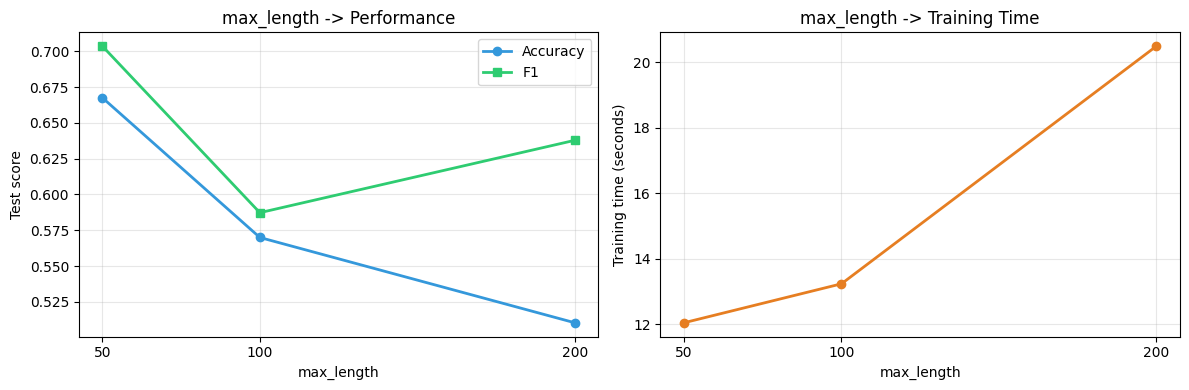

In [11]:
# Experiment 5: Sequence Length -- Theo doi Validation Loss, Memory va Ve 2 bieu do Trade-off
exp5_table = exp2_table.copy()
# Uoc tinh dung luong bo nho cho batch (batch_size * max_length * 8 bytes / 1024)
exp5_table['input_id_batch_memory_KiB'] = [round((BATCH_SIZE * ml * 8) / 1024, 2) for ml in exp5_table['max_length']]

print('=== KET QUA EXPERIMENT 5: SEQUENCE LENGTH & RESOURCE USAGE ===')
display(exp5_table[['max_length', 'token_retention_%', 'training_time_s', 'validation_loss', 'Accuracy', 'F1', 'input_id_batch_memory_KiB']])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
# Bieu do 1: max_length -> performance (Accuracy & F1)
axes[0].plot(exp5_table['max_length'], exp5_table['Accuracy'], marker='o', label='Accuracy', color='#3498db', lw=2)
axes[0].plot(exp5_table['max_length'], exp5_table['F1'], marker='s', label='F1', color='#2ecc71', lw=2)
axes[0].set(xlabel='max_length', ylabel='Test score', title='max_length -> Performance')
axes[0].set_xticks(exp5_table['max_length']); axes[0].legend(); axes[0].grid(alpha=0.3)

# Bieu do 2: max_length -> training time
axes[1].plot(exp5_table['max_length'], exp5_table['training_time_s'], marker='o', color='#e67e22', lw=2)
axes[1].set(xlabel='max_length', ylabel='Training time (seconds)', title='max_length -> Training Time')
axes[1].set_xticks(exp5_table['max_length']); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('sequence_length_tradeoff.png', dpi=120, bbox_inches='tight')
plt.show()


**Có tồn tại trade-off giữa context và computational cost không?**

Có. Kết quả thực nghiệm cho thấy sự đánh đổi giữa lượng ngữ cảnh được giữ lại và chi phí tính toán.

1. Khi tăng max_length từ 50 lên 200, tỷ lệ token được giữ lại tăng từ 21,7% lên 68,9%.
2. Thời gian huấn luyện tăng từ 12,04 giây lên 20,49 giây.
3. Dung lượng batch input_ids ước tính tăng từ 50 KiB lên 200 KiB, tương ứng gấp 4 lần.
4. F1 không tăng đơn điệu theo độ dài chuỗi: đạt 0,7035 tại 50 token, 0,5873 tại 100 token và 0,6378 tại 200 token.

Trong lần chạy này, giữ lại nhiều ngữ cảnh hơn làm tăng chi phí tính toán nhưng không bảo đảm cải thiện hiệu quả phân loại. Do mỗi cấu hình chỉ được chạy một lần, chưa thể kết luận sự khác biệt là ổn định hoặc xác định chính xác nguyên nhân.

#### 21. Experiment 6 — Long-range dependency

Kiểm tra độ nhạy của mô hình với vị trí từ khóa sắc thái (**Beginning**, **Middle**, **End**) trên câu văn bản tổng hợp.



In [12]:
filler = ('This movie had many different scenes with various actors. '
          'The cinematography was average and the pacing was slow. ')

test_reviews = [
    ('excellent! The movie was exciting from start. ' + filler,
     'beginning (excellent dau)'),
    (filler + ' excellent! ' + filler,
     'middle (excellent giua)'),
    (filler + ' excellent! The ending was perfect.',
     'end (excellent cuoi)'),
    ('terrible! The movie was disappointing from start. ' + filler,
     'beginning (terrible dau)'),
    (filler + ' terrible! ' + filler,
     'middle (terrible giua)'),
    (filler + ' terrible! The ending was dreadful.',
     'end (terrible cuoi)'),
]

print(f'{"Position":<35} {"Label":<12} {"P(positive)":<12}')
print('-' * 60)
best_lstm = trained_models['lstm']
for review_text, position in test_reviews:
    lbl, prob = predict_review(review_text, best_lstm, vocab, max_length=MAX_LEN, device=DEVICE)
    print(f'{position:<35} {lbl:<12} {prob:.4f}')

Position                            Label        P(positive) 
------------------------------------------------------------
beginning (excellent dau)           positive     0.8409
middle (excellent giua)             negative     0.1562
end (excellent cuoi)                negative     0.1563
beginning (terrible dau)            negative     0.1563
middle (terrible giua)              negative     0.1562
end (terrible cuoi)                 negative     0.1563


#### 22. Evaluation

Báo cáo đầy đủ các chỉ số: Accuracy, Precision, Recall, F1 cùng ma trận nhầm lẫn (**Confusion Matrix**) cho cả 3 mô hình recurrent.
Ngoài ra, báo cáo đầy đủ các thông số tài nguyên:
- **Số lượng tham số (Number of parameters)**
- **Thời gian huấn luyện (Training time)**
- **Số lượng epochs**
- **Độ dài chuỗi (Sequence length)**
- **Kích thước từ điển (Vocabulary size)**


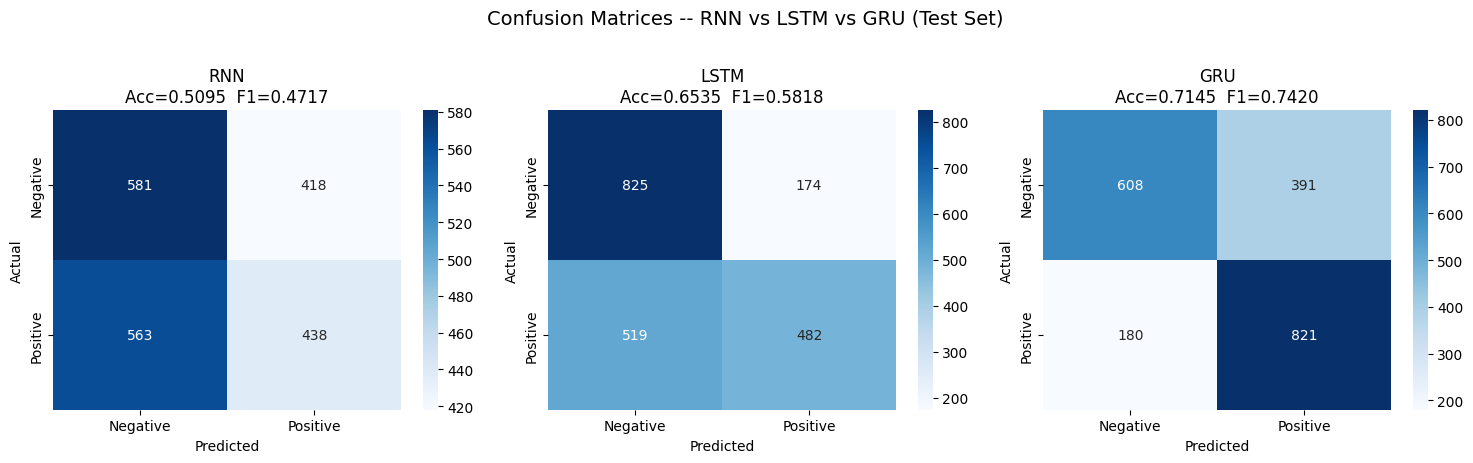

Da luu: confusion_matrix.png


In [13]:
# Su dung truc tiep 3 models da train tu Exp 4 (KHONG retrain ton thoi gian)
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

for ax, rnn_type in zip(axes, ['rnn', 'lstm', 'gru']):
    m_eval = trained_models[rnn_type]
    yt_e, yp_e, _ = get_predictions(m_eval, test_loader, DEVICE)
    cm = confusion_matrix(yt_e, yp_e)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['Negative','Positive'],
                yticklabels=['Negative','Positive'])
    mets_e = evaluate(yt_e, yp_e)
    ax.set_title(f'{rnn_type.upper()}\nAcc={mets_e["Accuracy"]:.4f}  F1={mets_e["F1"]:.4f}')
    ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')

plt.suptitle('Confusion Matrices -- RNN vs LSTM vs GRU (Test Set)', fontsize=14, y=1.02)
plt.tight_layout()
plt.savefig('confusion_matrix.png', dpi=120, bbox_inches='tight')
plt.show()
print('Da luu: confusion_matrix.png')

## Tổng hợp kết quả định lượng vào results.csv


In [14]:
# Luu results.csv theo format chuan giong LAB 03 va LAB 04
res_records = []

# Baseline
res_records.append({'experiment': 'exp3', 'setting': 'TF-IDF + LR', 'metric': 'Training time (s)', 'value': round(lr_time, 4)})
res_records.append({'experiment': 'exp3', 'setting': 'TF-IDF + LR', 'metric': 'Accuracy', 'value': round(metrics_lr['Accuracy'], 4)})
res_records.append({'experiment': 'exp3', 'setting': 'TF-IDF + LR', 'metric': 'F1', 'value': round(metrics_lr['F1'], 4)})

# Exp 4
for r_type in ['rnn', 'lstm', 'gru']:
    r = exp4_results[r_type]
    s_name = f'{r_type.upper()} + Embedding'
    res_records.append({'experiment': 'exp4', 'setting': s_name, 'metric': 'Training time (s)', 'value': float(r['Train time (s)'])});
    res_records.append({'experiment': 'exp4', 'setting': s_name, 'metric': 'Accuracy', 'value': float(r['Accuracy'])});
    res_records.append({'experiment': 'exp4', 'setting': s_name, 'metric': 'Precision', 'value': float(r['Precision'])});
    res_records.append({'experiment': 'exp4', 'setting': s_name, 'metric': 'Recall', 'value': float(r['Recall'])});
    res_records.append({'experiment': 'exp4', 'setting': s_name, 'metric': 'F1', 'value': float(r['F1'])});

# Exp 5
for _,item in exp5_table.iterrows():
    ml_name = f'max_length={item['max_length']}'
    res_records.append({'experiment': 'exp5', 'setting': ml_name, 'metric': 'Accuracy', 'value': float(item['Accuracy'])})
    res_records.append({'experiment': 'exp5', 'setting': ml_name, 'metric': 'F1', 'value': float(item['F1'])})

results_df = pd.DataFrame(res_records)
results_df.to_csv('results.csv', index=False)
print('Da luu: results.csv')
display(results_df.head(15))

Da luu: results.csv


,experiment,setting,metric,value
0,exp3,TF-IDF + LR,Training time (s),0.1570
1,exp3,TF-IDF + LR,Accuracy,0.8815
2,exp3,TF-IDF + LR,F1,0.8837
3,exp4,RNN + Embedding,Training time (s),24.9000
4,exp4,RNN + Embedding,Accuracy,0.5095
5,exp4,RNN + Embedding,Precision,0.5117
6,exp4,RNN + Embedding,Recall,0.4376
7,exp4,RNN + Embedding,F1,0.4717
8,exp4,LSTM + Embedding,Training time (s),23.0000
9,exp4,LSTM + Embedding,Accuracy,0.6535


#### 23. Learning curves



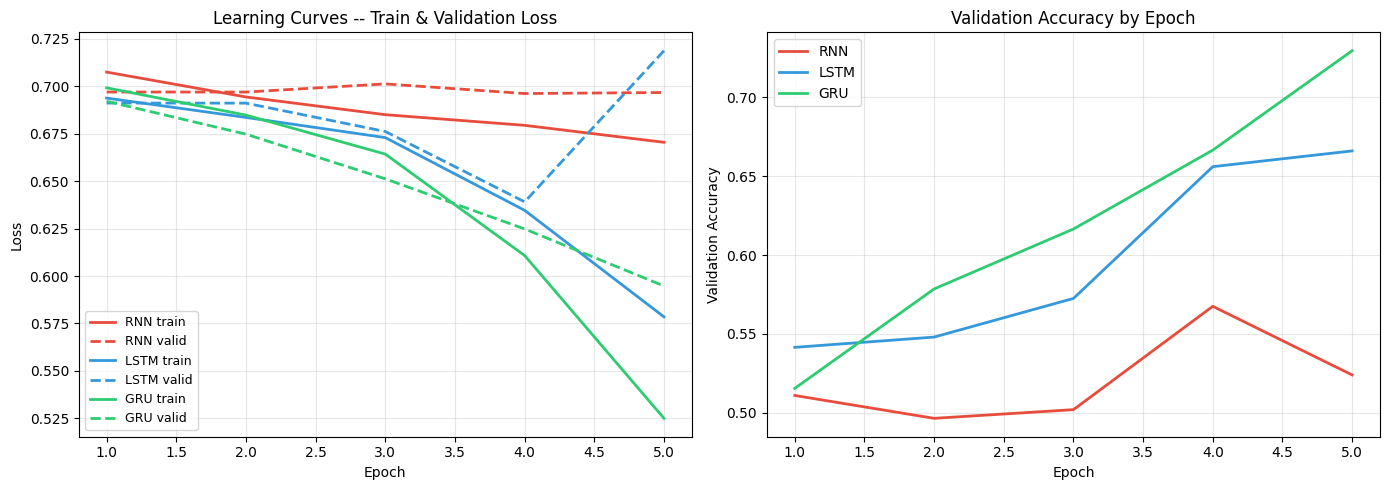

Da luu: learning_curves.png


In [15]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
colors = {'rnn': '#e74c3c', 'lstm': '#3498db', 'gru': '#2ecc71'}

for rnn_type, hist in exp4_histories.items():
    epochs = range(1, len(hist['train_losses']) + 1)
    axes[0].plot(epochs, hist['train_losses'], label=f'{rnn_type.upper()} train', color=colors[rnn_type], lw=2)
    axes[0].plot(epochs, hist['valid_losses'], label=f'{rnn_type.upper()} valid', color=colors[rnn_type], lw=2, ls='--')

axes[0].set_xlabel('Epoch'); axes[0].set_ylabel('Loss')
axes[0].set_title('Learning Curves -- Train & Validation Loss'); axes[0].legend(fontsize=9); axes[0].grid(alpha=0.3)

for rnn_type, hist in exp4_histories.items():
    epochs = range(1, len(hist['valid_accs']) + 1)
    axes[1].plot(epochs, hist['valid_accs'], label=rnn_type.upper(), color=colors[rnn_type], lw=2)

axes[1].set_xlabel('Epoch'); axes[1].set_ylabel('Validation Accuracy')
axes[1].set_title('Validation Accuracy by Epoch'); axes[1].legend(); axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.savefig('learning_curves.png', dpi=120, bbox_inches='tight')
plt.show()
print('Da luu: learning_curves.png')

Model có dấu hiệu overfitting không?

- **RNN:** training loss giảm từ 0,7074 xuống 0,6704, trong khi validation loss dao động quanh 0,697. Điều này cho thấy training loss cải thiện nhưng chất lượng trên validation chưa cải thiện rõ rệt.
- **LSTM:** training loss giảm từ 0,6937 xuống 0,5785. Validation loss giảm đến epoch 4 (0,6391), sau đó tăng lên 0,7187 ở epoch 5. Đây là dấu hiệu đáng chú ý của khả năng overfitting hoặc dự đoán kém hiệu chỉnh hơn ở epoch cuối.
- **GRU:** training loss giảm từ 0,6991 xuống 0,5250 và validation loss giảm từ 0,6921 xuống 0,5947 trong cả 5 epoch. Chưa thấy dấu hiệu overfitting rõ ràng từ validation loss trong phạm vi quan sát này.

**Kết luận:** LSTM có dấu hiệu cần theo dõi overfitting ở epoch cuối; RNN có dấu hiệu học chưa hiệu quả; còn GRU tiếp tục cải thiện trên validation trong 5 epoch.



#### 24. Error analysis

Chọn ít nhất 3 mẫu dự đoán đúng (**Correct**) và 3-4 mẫu dự đoán sai (**Incorrect**) từ mô hình LSTM.
Với từng lỗi sai, xem xét các yếu tố: negation, long-range dependency, sarcasm, ambiguous sentiment, rare word, domain-specific term, sequence length / truncation, noise.
**Xác định rõ:** Lỗi này có phải do sequence modeling hay không? Không được mặc định *"LSTM không hiểu câu"*.


In [16]:
y_true_ea, y_pred_ea, y_prob_ea = get_predictions(trained_models['lstm'], test_loader, DEVICE)
label_map = {0: 'negative', 1: 'positive'}
correct_idx   = np.where(y_true_ea == y_pred_ea)[0]
incorrect_idx = np.where(y_true_ea != y_pred_ea)[0]
rng_ea = np.random.default_rng(42)
chosen_c = rng_ea.choice(correct_idx, size=3, replace=False)
chosen_e = rng_ea.choice(incorrect_idx, size=4, replace=False)

print('=== CORRECTLY CLASSIFIED (3 samples) ===')
for i, idx in enumerate(chosen_c, 1):
    t = X_test[idx][:250] + '...'
    print(f'\n[C{i}] True={label_map[y_true_ea[idx]]}  Pred={label_map[y_pred_ea[idx]]}  P(pos)={y_prob_ea[idx]:.4f}')
    print(f'     {t}')

print('\n=== INCORRECTLY CLASSIFIED (4 samples) ===')
for i, idx in enumerate(chosen_e, 1):
    t = X_test[idx][:250] + '...'
    print(f'\n[E{i}] True={label_map[y_true_ea[idx]]}  Pred={label_map[y_pred_ea[idx]]}  P(pos)={y_prob_ea[idx]:.4f}')
    print(f'     {t}')

=== CORRECTLY CLASSIFIED (3 samples) ===

[C1] True=negative  Pred=negative  P(pos)=0.1449
     To truly appreciate this film you had to be there (acting?) or have been a crew member. Yes, I am "Selena", and at the ripe old age of 42, have serious doubts about what we were doing/did. It all started out to be like a "John Waters" type thing, fri...

[C2] True=negative  Pred=negative  P(pos)=0.2048
     Why is it that every time I mention this movie to somebody, I have to hear 10 minutes of praise about it. I have come to the conclusion that any movie that has a twist upon a twist is deemed "genius" by anyone who watches it. Is that really what film...

[C3] True=negative  Pred=negative  P(pos)=0.2653
     National Treasure is about as over-rated and over-hyped as they come. Nicholas Cage is in no way a believable action hero, and this film is no "Indiana Jones". People who have compared this movie to the Indian Jones classic trilogy have seriously fal...

=== INCORRECTLY CLASSIFIED (4 s

#### 25. So sánh với LAB 04

### Bảng đối chiếu đặc tính 5 mô hình:
| Đặc điểm (Property) | TF-IDF + LR | Avg Word2Vec + LR | Simple RNN | LSTM | GRU |
|---|:---:|:---:|:---:|:---:|:---:|
| **Sparse representation** | Có (✓) | Không (✗) | Không (✗) | Không (✗) | Không (✗) |
| **Dense representation** | Không (✗) | Có (✓) | Có (✓) | Có (✓) | Có (✓) |
| **Word order** | Hạn chế (Limited) | Không (✗) | **Có (✓)** | **Có (✓)** | **Có (✓)** |
| **Context-dependent state** | Không (✗) | Không (✗) | **Có (✓)** | **Có (✓)** | **Có (✓)** |
| **Long dependency** | Không (✗) | Không (✗) | Hạn chế (Limited) | **Cải thiện (Improved)** | **Cải thiện (Improved)** |
| **Computational cost** | Thấp (Low) | Thấp (Low) | Cao hơn (Higher) | Cao hơn (Higher) | Cao hơn (Higher) |
| **One vector per word** | Có (✓) | Có (✓) | Embedding | Embedding | Embedding |

1. **RNN/LSTM/GRU giải quyết được vấn đề gì mà Average Word2Vec không giải quyết tốt?**
   - **Bảo toàn thứ tự từ (Word order):** Phân biệt được các câu hoán đổi vị trí từ và nắm bắt được ngữ cảnh phủ định (*"not bad"* khác hoàn toàn *"bad"*).
   - **Trạng thái ẩn phụ thuộc ngữ cảnh (Context-dependent state):** Trạng thái ẩn $h_t$ thay đổi linh hoạt theo các từ đứng trước, không bị san phẳng thành một vector trung bình tĩnh.
2. **Mô hình Sequence vẫn còn những hạn chế gì?**
   - **Nút thắt cổ chai thông tin (Information Bottleneck):** Toàn bộ câu dài bị nén vào một vector $h_T$ duy nhất tại bước cuối cùng.
   - **Nút thắt cổ chai tính toán (Sequential Bottleneck):** Phải tính tuần tự từng bước $t$, không thể song song hóa trên GPU. Đây chính là động lực khai sinh ra kiến trúc **Transformer**.


#### 26. Application

Xây dựng bộ phân loại cảm xúc hoàn chỉnh:
$$\text{Raw review} \longrightarrow \text{Tokenizer} \longrightarrow \text{Vocabulary} \longrightarrow \text{Token IDs} \longrightarrow \text{Padding/truncation} \longrightarrow \text{Embedding} \longrightarrow \text{LSTM/GRU} \longrightarrow \text{Linear layer} \longrightarrow \text{Sentiment}$$

Thử nghiệm trên 4 dạng bài đánh giá:
1. Review ngắn (*short*)
2. Review dài (*long*)
3. Review có chứa từ phủ định (*negation*)
4. Review có cấu trúc tương phản chuyển ý (*contrast*)


In [17]:
app_tests = [
    ('I really enjoyed this movie.', 'short'),
    ('This film masterfully blends action and emotion. The director shows extraordinary '
     'vision with sweeping cinematography and powerful performances from the entire cast. '
     'A storyline that manages to be both epic in scope and deeply personal. '
     'Every scene feels purposeful. An absolute triumph.', 'long'),
    ('I did not like this movie at all. The story was not engaging, '
     'the characters were not believable, the ending was not satisfying.', 'negation'),
    ('Despite a slow start and some pacing issues, the film ultimately delivers '
     'a powerful and deeply moving conclusion that makes it entirely worth watching.', 'contrast'),
]

print(f'{"Type":<12} {"Predicted":<12} {"P(positive)":<12} {"Text":<50}')
print('-' * 85)
for text_sample, kind in app_tests:
    lbl, p = predict_review(text_sample, trained_models['lstm'], vocab, max_length=MAX_LEN, device=DEVICE)
    print(f'{kind:<12} {lbl:<12} {p:<12.4f} "{text_sample[:45]}..."')

Type         Predicted    P(positive)  Text                                              
-------------------------------------------------------------------------------------
short        positive     0.8409       "I really enjoyed this movie...."
long         positive     0.8409       "This film masterfully blends action and emoti..."
negation     negative     0.1563       "I did not like this movie at all. The story w..."
contrast     negative     0.1563       "Despite a slow start and some pacing issues, ..."
